In [ ]:
!pip install keras-tuner --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 5.1 MB/s eta 0:00:00


## Supervised Classification

### 1. Load data

In [ ]:
import os
DATASET_DIR = os.environ.get("BISCUIT_DATA_DIR", "../../data/DS_multiclass")  # built by 00_data_prep/prepare_data.py

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.19.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
IMG_SIZE = (256, 256)
BATCH_SIZE = 32

train_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "train"),
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

valid_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "valid"),
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "test"),
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)


Found 3918 files belonging to 4 classes.
Found 490 files belonging to 4 classes.
Found 492 files belonging to 4 classes.


In [ ]:
class_names = train_ds_raw.class_names
class_names

['Defect_Color', 'Defect_No', 'Defect_Object', 'Defect_Shape']

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds_raw.prefetch(AUTOTUNE)
valid_ds = valid_ds_raw.prefetch(AUTOTUNE)
test_ds = test_ds_raw.prefetch(AUTOTUNE)

In [ ]:
import matplotlib.pyplot as plt

def plot_training_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs = range(1, len(acc)+1)

    plt.figure(figsize=(12,5))

    # Accuracy
    plt.subplot(1,2,1)
    plt.plot(epochs, acc, 'b-', label="Training Acc")
    plt.plot(epochs, val_acc, 'r-', label="Validation Acc")
    plt.title("Accuracy Over Epochs")
    plt.legend()

    # Loss
    plt.subplot(1,2,2)
    plt.plot(epochs, loss, 'b-', label="Training Loss")
    plt.plot(epochs, val_loss, 'r-', label="Validation Loss")
    plt.title("Loss Over Epochs")
    plt.legend()

    plt.show()


In [ ]:
import numpy as np
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve
)
import matplotlib.pyplot as plt

def evaluate_model(model, test_ds, class_names):
    # -----------------------------
    # 1. Collect all predictions
    # -----------------------------
    y_true = []
    y_pred = []

    for img, label in test_ds:
        preds = model.predict(img)
        y_true.extend(np.argmax(label.numpy(), axis=1))
        y_pred.extend(np.argmax(preds, axis=1))

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # -----------------------------
    # 2. Confusion Matrix
    # -----------------------------
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d",
                xticklabels=class_names,
                yticklabels=class_names,
                cmap="Blues")
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    # -----------------------------
    # 3. Classification Report
    # -----------------------------
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # -----------------------------
    # 4. Misclassified Samples
    # -----------------------------
    print("Showing some misclassified samples...")

    incorrect_idx = np.where(y_true != y_pred)[0]
    if len(incorrect_idx) == 0:
        print("No misclassified samples!")
        return

    plt.figure(figsize=(12,7))
    for i, idx in enumerate(incorrect_idx[:6]):
        img, label = list(test_ds.unbatch().take(idx+1))[idx]
        plt.subplot(2,3,i+1)
        plt.imshow(img.numpy().astype("uint8"))
        plt.title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}")
        plt.axis("off")

    plt.show()


### 2. CNN Model

2.2 Advanced CNN

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
import keras_tuner as kt

IMG_SIZE = (256, 256)
NUM_CLASSES = 4

def build_advanced_cnn_model(hp):
    # reg rate
    l2_reg = hp.Choice("l2_reg", [1e-3, 1e-4, 1e-5])

    # Dropout
    dropout_rate = hp.Choice("dropout", [0.3, 0.4, 0.5])

    # Dense units
    dense_units = hp.Choice("dense_units", [64, 128, 256])

    # Learning rate
    lr = hp.Choice("learning_rate", [1e-3, 3e-4, 1e-4, 3e-5])

    model = models.Sequential([
        layers.Rescaling(1./255, input_shape=(256,256,3)),

        # Block 1
        layers.Conv2D(32, 3, padding="same",
            kernel_regularizer=regularizers.l2(l2_reg)),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.MaxPooling2D(),

        # Block 2
        layers.Conv2D(64, 3, padding="same",
            kernel_regularizer=regularizers.l2(l2_reg)),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.MaxPooling2D(),

        # Block 3
        layers.Conv2D(128, 3, padding="same",
            kernel_regularizer=regularizers.l2(l2_reg)),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),
        layers.Dense(dense_units, activation="relu",
             kernel_regularizer=regularizers.l2(l2_reg)),
        layers.Dropout(dropout_rate),

        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


In [ ]:
tuner = kt.Hyperband(
    build_advanced_cnn_model,
    objective='val_accuracy',
    max_epochs=10,
    factor=3,
    directory='tuner_dir',
    project_name='adv_cnn'
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
stop_early = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2)

tuner.search(
    train_ds_raw,
    validation_data=valid_ds_raw,
    epochs=10,
    callbacks=[stop_early]
)

Trial 30 Complete [00h 01m 03s]
val_accuracy: 0.41632652282714844

Best val_accuracy So Far: 0.9020408391952515
Total elapsed time: 00h 28m 39s


In [ ]:
best_hp = tuner.get_best_hyperparameters(1)[0]
best_hp.values

{'l2_reg': 1e-05,
 'dropout': 0.4,
 'dense_units': 64,
 'learning_rate': 0.0003,
 'tuner/epochs': 10,
 'tuner/initial_epoch': 4,
 'tuner/bracket': 2,
 'tuner/round': 2,
 'tuner/trial_id': '0014'}

In [ ]:
adv_model = build_advanced_cnn_model(best_hp)

history = adv_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=30,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ]
)

Epoch 1/30


/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


123/123 ━━━━━━━━━━━━━━━━━━━━ 29s 177ms/step - accuracy: 0.5358 - loss: 1.0615 - val_accuracy: 0.3796 - val_loss: 1.7947
Epoch 2/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 15s 120ms/step - accuracy: 0.7573 - loss: 0.6642 - val_accuracy: 0.3796 - val_loss: 3.5964
Epoch 3/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 15s 121ms/step - accuracy: 0.7963 - loss: 0.5626 - val_accuracy: 0.3898 - val_loss: 3.0887
Epoch 4/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 15s 121ms/step - accuracy: 0.8350 - loss: 0.4759 - val_accuracy: 0.4245 - val_loss: 2.8490
Epoch 5/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 15s 121ms/step - accuracy: 0.8646 - loss: 0.4268 - val_accuracy: 0.5204 - val_loss: 0.9346
Epoch 6/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 15s 120ms/step - accuracy: 0.8821 - loss: 0.3778 - val_accuracy: 0.8429 - val_loss: 0.4820
Epoch 7/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 21s 121ms/step - accuracy: 0.8947 - loss: 0.3566 - val_accuracy: 0.7857 - val_loss: 0.5870
Epoch 8/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 15s 121ms/step - accuracy: 0.8993 - loss: 0.3363 - val

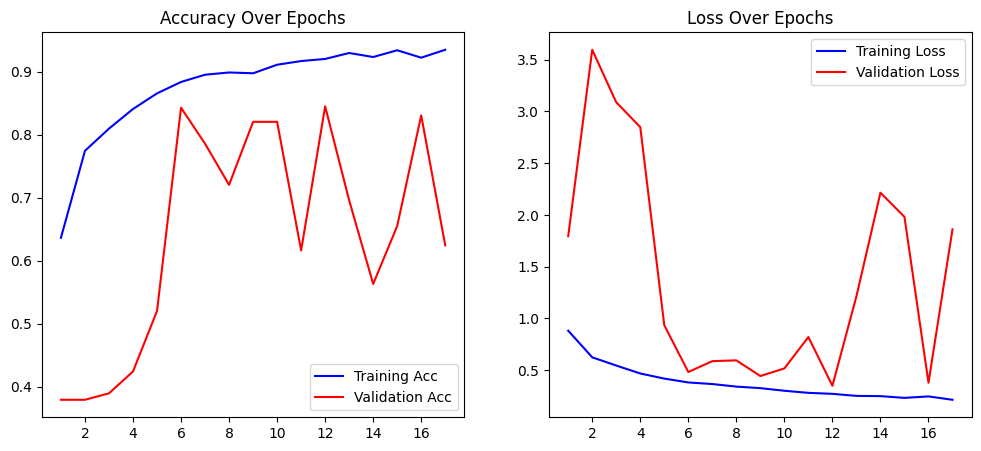

In [ ]:
plot_training_history(history)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 685ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 585ms/step


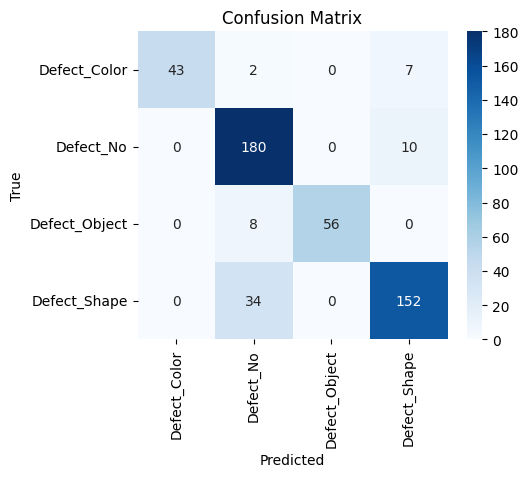


Classification Report:
               precision    recall  f1-score   support

 Defect_Color       1.00      0.83      0.91        52
    Defect_No       0.80      0.95      0.87       190
Defect_Object       1.00      0.88      0.93        64
 Defect_Shape       0.90      0.82      0.86       186

     accuracy                           0.88       492
    macro avg       0.93      0.87      0.89       492
 weighted avg       0.89      0.88      0.88       492

Showing some misclassified samples...


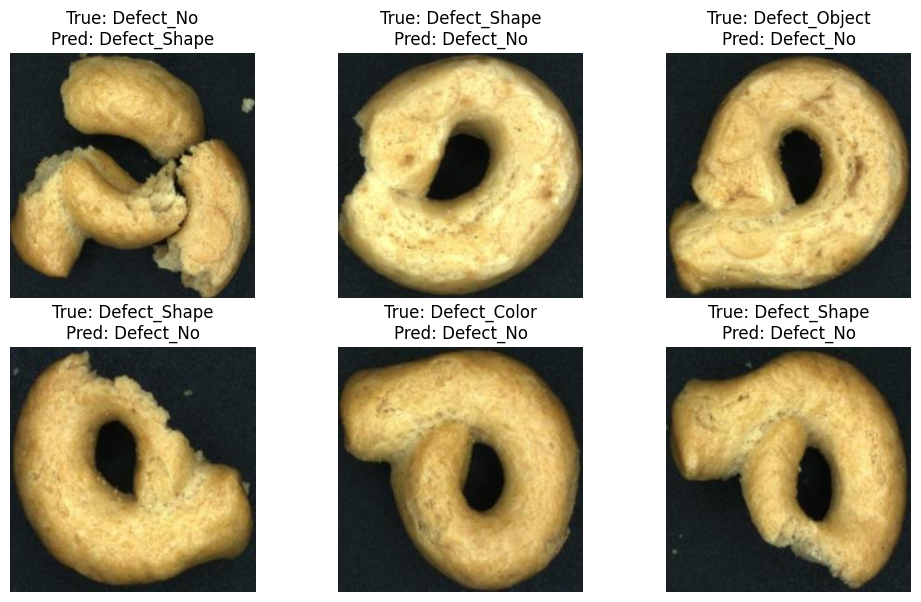

In [ ]:
evaluate_model(adv_model, test_ds, class_names)


Actually here the misclassified samples' images and labels are not consistent. Apologize for the mistake. Please just ingnore that.